# Smart Photo Repair
### Context-Aware Selective Image Enhancement Using Computer Vision
*"Repair the region, not the image."*

**Pipeline:** Upload → Segment (SAM click / YOLO person) → Analyze region → Diagnose → Correct only inside mask → Blend with original → Before/After

**Core equation:** `I'(x,y) = M(x,y)·F(I(x,y)) + (1 − M(x,y))·I(x,y)`

**Setup:** Runtime → Change runtime type → **T4 GPU**, then Run all.

## 1. Setup (installs + SAM checkpoint)

In [3]:
!pip install -q ultralytics segment-anything gradio

# Native Python download to avoid needing 'wget' on Windows
import urllib.request
import os

url = "https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth"
filename = "sam_vit_b_01ec64.pth"

if not os.path.exists(filename):
    print("Downloading SAM checkpoint...")
    urllib.request.urlretrieve(url, filename)
    print("Download complete!")
else:
    print("SAM checkpoint already exists.")

Download complete!


In [4]:
!pip install -q ultralytics segment-anything gradio
!wget -q -nc https://dl.fbaipublicfiles.com/segment_anything/sam_vit_b_01ec64.pth

'wget' is not recognized as an internal or external command,
operable program or batch file.


## 2. Imports and model loading
YOLOv8-seg finds people; SAM (ViT-B) turns a click into a pixel-level mask.

In [5]:
import cv2, numpy as np, torch, gradio as gr
import matplotlib.pyplot as plt
from ultralytics import YOLO
from segment_anything import sam_model_registry, SamPredictor

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Running on:", device)

sam = sam_model_registry["vit_b"](checkpoint="sam_vit_b_01ec64.pth").to(device)
predictor = SamPredictor(sam)
yolo = YOLO("yolov8n-seg.pt")

Running on: cpu


## 3. Mask utilities and blending
Mask `M = 1` → modify, `M = 0` → preserve. Feathering softens the edge so the correction blends naturally.

In [6]:
def feather_mask(mask, sigma=4):
    m = mask.astype(np.float32)
    if sigma > 0:
        m = cv2.GaussianBlur(m, (0, 0), sigma)
    return np.clip(m, 0, 1)

def blend(original, corrected, mask):
    # I' = M * F(I) + (1 - M) * I
    m = mask[..., None]
    out = m * corrected.astype(np.float32) + (1 - m) * original.astype(np.float32)
    return np.clip(out, 0, 255).astype(np.uint8)

def overlay_mask(img, mask, color=(0, 255, 0), alpha=0.45):
    m = (mask > 0.5)
    out = img.copy().astype(np.float32)
    out[m] = (1 - alpha) * out[m] + alpha * np.array(color, dtype=np.float32)
    out = out.astype(np.uint8)
    contours, _ = cv2.findContours(m.astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    cv2.drawContours(out, contours, -1, color, 2)
    return out

## 4. Region analysis and problem detection
Uses the **L (lightness) channel of LAB** and simple statistics: mean, spread, shadow/highlight fractions, and subject-vs-background difference.

In [7]:
UNDER_T = 90        # mean L below this -> underexposed
OVER_T = 180        # mean L above this -> overexposed
TARGET_L = 120      # desired mean lightness after repair
BACKLIGHT_GAP = 40  # background brighter than subject by this much -> backlit
LOW_CONTRAST_STD = 35
CLIP_FRAC = 0.05

def lightness(img_rgb):
    return cv2.cvtColor(img_rgb, cv2.COLOR_RGB2LAB)[..., 0].astype(np.float32)  # 0-255 for uint8

def analyze_region(img, mask):
    L = lightness(img)
    sel = mask > 0.5
    if sel.sum() < 50:
        raise ValueError("Selected region is too small to analyze.")
    subj = L[sel]
    bg = L[~sel]
    info = {
        "mean": float(subj.mean()),
        "std": float(subj.std()),
        "shadow_frac": float((subj < 40).mean()),
        "highlight_frac": float((subj > 240).mean()),
        "bg_mean": float(bg.mean()) if bg.size else None,
    }
    if info["mean"] < UNDER_T:
        info["status"] = "underexposed"
    elif info["mean"] > OVER_T:
        info["status"] = "overexposed"
    else:
        info["status"] = "ok"
    info["backlit"] = (info["bg_mean"] is not None and
                       info["bg_mean"] - info["mean"] > BACKLIGHT_GAP and
                       info["status"] == "underexposed")
    info["low_contrast"] = info["std"] < LOW_CONTRAST_STD
    info["clipped_highlights"] = info["highlight_frac"] > CLIP_FRAC

    # gamma exponent that moves the region's mean lightness toward TARGET_L
    m = float(np.clip(info["mean"], 5, 250))
    exp = np.log(TARGET_L / 255.0) / np.log(m / 255.0)
    info["gamma_exp"] = float(np.clip(exp, 0.4, 2.0))
    return info

def describe(info):
    bg = f"{info['bg_mean']:.0f}" if info["bg_mean"] is not None else "n/a"
    lines = [
        f"Region mean lightness : {info['mean']:.0f} / 255",
        f"Background mean       : {bg} / 255",
        f"Contrast (std)        : {info['std']:.0f}",
        f"Verdict               : {info['status'].upper()}",
    ]
    if info["backlit"]:
        lines.append("Warning               : strong backlighting detected")
    if info["low_contrast"]:
        lines.append("Warning               : low contrast in region")
    if info["clipped_highlights"]:
        lines.append("Warning               : clipped highlights in region")
    return lines

## 5. Correction functions (the `F(I)` in the equation)
Each is a plain, deterministic image-processing operation on the whole image; the mask later decides where it actually applies.

In [8]:
def adjust_gamma(img, exponent):
    lut = (255.0 * (np.arange(256) / 255.0) ** exponent).clip(0, 255).astype(np.uint8)
    return cv2.LUT(img, lut)

def adjust_brightness_contrast(img, brightness=0, contrast=1.0):
    # I' = alpha * (I - 128) + 128 + beta
    out = (img.astype(np.float32) - 128) * contrast + 128 + brightness
    return np.clip(out, 0, 255).astype(np.uint8)

def adjust_saturation(img, factor):
    hsv = cv2.cvtColor(img, cv2.COLOR_RGB2HSV).astype(np.float32)
    hsv[..., 1] = np.clip(hsv[..., 1] * factor, 0, 255)
    return cv2.cvtColor(hsv.astype(np.uint8), cv2.COLOR_HSV2RGB)

def adjust_warmth(img, amount):
    out = img.astype(np.float32)
    out[..., 0] += amount   # red up
    out[..., 2] -= amount   # blue down
    return np.clip(out, 0, 255).astype(np.uint8)

def sharpen(img, amount):
    blur = cv2.GaussianBlur(img, (0, 0), 2)
    return cv2.addWeighted(img, 1 + amount, blur, -amount, 0)

def recover_highlights(img, amount=0.5):
    f = img.astype(np.float32)
    over = np.clip((f - 180) / 75.0, 0, 1)
    return np.clip(f - amount * over * (f - 180), 0, 255).astype(np.uint8)

def add_glow(img, strength=0.5, sigma=15):
    # soft bloom: blur the bright parts and combine using a "screen" blend
    f = img.astype(np.float32) / 255.0
    bright = np.clip(f - 0.5, 0, 1) * 2
    halo = cv2.GaussianBlur(bright, (0, 0), sigma)
    out = 1 - (1 - f) * (1 - strength * halo)
    return (np.clip(out, 0, 1) * 255).astype(np.uint8)

def blur_image(img, sigma):
    return cv2.GaussianBlur(img, (0, 0), sigma) if sigma > 0 else img

## 6. Editing modes
**Manual**, **Smart Repair** (detect → diagnose → correct), **Smart Glow**, and **Focus** (subject up, background down).

In [9]:
def manual_edit(img, brightness, contrast, saturation, warmth, sharpness, glow):
    out = adjust_brightness_contrast(img, brightness, contrast)
    out = adjust_saturation(out, saturation)
    out = adjust_warmth(out, warmth)
    if sharpness > 0: out = sharpen(out, sharpness)
    if glow > 0: out = add_glow(out, glow)
    return out

def smart_repair(img, mask):
    info = analyze_region(img, mask)
    out, actions = img.copy(), []
    if info["status"] in ("underexposed", "overexposed"):
        out = adjust_gamma(out, info["gamma_exp"])
        verb = "Brightened" if info["gamma_exp"] < 1 else "Darkened"
        actions.append(f"{verb} region (gamma exponent {info['gamma_exp']:.2f})")
    if info["clipped_highlights"]:
        out = recover_highlights(out, 0.5)
        actions.append("Recovered clipped highlights")
    if info["low_contrast"]:
        out = adjust_brightness_contrast(out, 0, 1.2)
        actions.append("Boosted contrast x1.2")
    if not actions:
        actions.append("Region already looks fine: nothing changed")
    return out, info, actions

def smart_glow(img, mask, glow_strength=0.6):
    info = analyze_region(img, mask)
    exp = info["gamma_exp"] if info["status"] == "underexposed" else 0.85
    out = adjust_gamma(img, exp)
    out = recover_highlights(out, 0.3)
    out = add_glow(out, glow_strength, sigma=18)
    return out, info, [f"Lifted exposure (gamma exponent {exp:.2f})",
                       "Softened highlights", f"Added local glow (strength {glow_strength})"]

def focus_mode(img, mask, bg_dim=0.75, bg_blur=6):
    info = analyze_region(img, mask)
    subject = adjust_gamma(img, min(info["gamma_exp"], 1.0)) if info["status"] != "overexposed" else img
    subject = sharpen(subject, 0.6)
    background = (img.astype(np.float32) * bg_dim).astype(np.uint8)
    background = adjust_saturation(background, 0.7)
    background = blur_image(background, bg_blur)
    # subject and background are edited differently, then joined by the mask
    out = blend(background, subject, mask)
    return out, info, ["Brightened and sharpened subject",
                       f"Dimmed background x{bg_dim}, desaturated, blurred (sigma {bg_blur})"]

## 7. Sanity test (no models or upload needed)
A synthetic backlit scene: dark subject in front of a bright window. Only the subject should change.

Region mean lightness : 42 / 255
Background mean       : 215 / 255
Contrast (std)        : 0
Verdict               : UNDEREXPOSED
Actions: ['Brightened region (gamma exponent 0.42)', 'Boosted contrast x1.2']
Background mean before/after: 210.0 / 210.3  (should be ~equal)


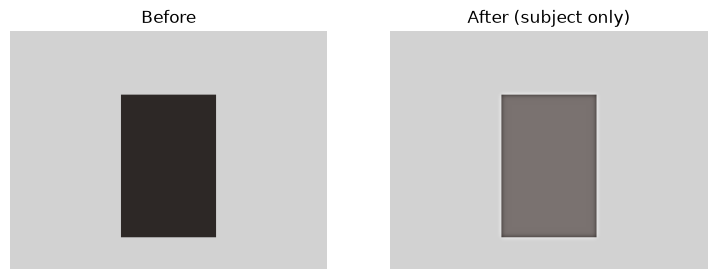

In [10]:
test = np.full((300, 400, 3), 210, np.uint8)            # bright background
test[80:260, 140:260] = (45, 40, 38)                    # dark subject
test_mask = np.zeros((300, 400), np.float32)
test_mask[80:260, 140:260] = 1

soft = feather_mask(test_mask, 3)
corrected, info, actions = smart_repair(test, soft)
result = blend(test, corrected, soft)

print("\n".join(describe(info))); print("Actions:", actions)
bg_before = test[test_mask == 0].mean(); bg_after = result[test_mask == 0].mean()
print(f"Background mean before/after: {bg_before:.1f} / {bg_after:.1f}  (should be ~equal)")

fig, ax = plt.subplots(1, 2, figsize=(9, 3.5))
ax[0].imshow(test); ax[0].set_title("Before"); ax[0].axis("off")
ax[1].imshow(result); ax[1].set_title("After (subject only)"); ax[1].axis("off")
plt.show()

## 8. Segmentation helpers
- **Click → SAM** point prompt gives a mask.
- **YOLOv8-seg** detects people and lets you pick one from a list.

Images are downscaled to max 1024 px for speed. State is kept in a module-level dict, fine for a single-user demo.

In [11]:
STATE = {"img": None, "mask": None, "person_masks": []}
MAX_SIDE = 1024

def on_upload(img):
    if img is None:
        return None, "Upload an image."
    h, w = img.shape[:2]
    scale = MAX_SIDE / max(h, w)
    if scale < 1:
        img = cv2.resize(img, (int(w * scale), int(h * scale)), interpolation=cv2.INTER_AREA)
    STATE.update(img=img, mask=None, person_masks=[])
    predictor.set_image(img)  # compute SAM image embedding once
    return img, "Image loaded. Click the object you want to edit, or press 'Detect people'."

def on_click(evt: gr.SelectData):
    if STATE["img"] is None:
        return None, "Upload an image first."
    x, y = evt.index
    masks, scores, _ = predictor.predict(point_coords=np.array([[x, y]]),
                                         point_labels=np.array([1]),
                                         multimask_output=True)
    best = masks[int(np.argmax(scores))].astype(np.float32)
    STATE["mask"] = best
    return overlay_mask(STATE["img"], best), f"Region selected at ({x},{y}): {best.mean()*100:.1f}% of the image."

def detect_people():
    if STATE["img"] is None:
        return gr.update(), None, "Upload an image first."
    img = STATE["img"]
    r = yolo(img, verbose=False)[0]
    masks, labels = [], []
    if r.masks is not None:
        for cls, conf, poly in zip(r.boxes.cls.cpu().numpy(), r.boxes.conf.cpu().numpy(), r.masks.xy):
            if int(cls) == 0 and len(poly) > 2:
                m = np.zeros(img.shape[:2], np.uint8)
                cv2.fillPoly(m, [poly.astype(np.int32)], 1)
                masks.append(m.astype(np.float32))
                labels.append(f"Person {len(masks)} (conf {conf:.2f})")
    STATE["person_masks"] = masks
    if not masks:
        return gr.update(choices=[], value=None), None, "No people detected. Try clicking the object instead."
    STATE["mask"] = masks[0]
    return (gr.update(choices=labels, value=labels[0]),
            overlay_mask(img, masks[0]), f"{len(masks)} person(s) detected. Person 1 selected.")

def choose_person(label):
    if not label:
        return None, "No person selected."
    idx = int(label.split()[1]) - 1
    STATE["mask"] = STATE["person_masks"][idx]
    return overlay_mask(STATE["img"], STATE["mask"]), f"{label.split(' (')[0]} selected."

## 9. Apply the edit
The same function handles every mode and always finishes with the mask blend.

In [12]:
def run_edit(mode, invert, feather, brightness, contrast, saturation, warmth,
             sharpness, glow, bg_dim, bg_blur):
    img, mask = STATE["img"], STATE["mask"]
    if img is None or mask is None:
        return None, None, "Select a region first (click the image or detect people)."
    m = 1 - mask if invert else mask
    soft = feather_mask(m, feather)

    try:
        if mode == "Manual":
            corrected = manual_edit(img, brightness, contrast, saturation, warmth, sharpness, glow)
            result = blend(img, corrected, soft)
            info, actions = analyze_region(img, m), ["Applied manual slider values inside the mask only"]
        elif mode == "Smart Repair":
            corrected, info, actions = smart_repair(img, m)
            result = blend(img, corrected, soft)
        elif mode == "Smart Glow":
            corrected, info, actions = smart_glow(img, m, glow_strength=max(glow, 0.3))
            result = blend(img, corrected, soft)
        else:  # Focus Mode
            corrected, info, actions = focus_mode(img, m, bg_dim, bg_blur)
            result = corrected
    except ValueError as e:
        return img, None, str(e)

    after = analyze_region(result, m)
    bg_mask = m < 0.5
    drift = abs(float(lightness(result)[bg_mask].mean()) - float(lightness(img)[bg_mask].mean())) if bg_mask.any() else 0
    report = ["BEFORE"] + describe(info) + ["", "ACTIONS"] + ["- " + a for a in actions] + [
        "", "AFTER", f"Region mean lightness : {after['mean']:.0f} / 255 ({after['status']})"]
    if mode != "Focus Mode":
        report.append(f"Outside-region change : {drift:.1f} lightness levels (preserved)")
    return img, result, "\n".join(report)

## 10. Gradio interface
Run this cell and open the public link (or use the inline UI). Workflow: **upload → click the object (or Detect people) → choose mode → Apply**.

In [ ]:
with gr.Blocks(title="Smart Photo Repair") as demo:
    gr.Markdown("# Smart Photo Repair\n*Repair the region, not the image.*")
    with gr.Row():
        with gr.Column():
            inp = gr.Image(label="1. Upload, then CLICK the object to edit", type="numpy")
            status = gr.Textbox(label="Status", interactive=False)
            with gr.Row():
                detect_btn = gr.Button("Detect people (YOLO)")
                person_dd = gr.Dropdown(label="Detected people", choices=[])
        with gr.Column():
            mask_view = gr.Image(label="Selected region", interactive=False)
            mode = gr.Radio(["Smart Repair", "Manual", "Smart Glow", "Focus Mode"],
                            value="Smart Repair", label="2. Mode")
            invert = gr.Checkbox(label="Edit everything EXCEPT the selection (e.g. fix the background)")
            feather = gr.Slider(0, 15, value=4, step=1, label="Mask edge feathering")
            with gr.Accordion("Manual / Glow controls", open=False):
                brightness = gr.Slider(-100, 100, 0, step=1, label="Brightness")
                contrast = gr.Slider(0.5, 2.0, 1.0, step=0.05, label="Contrast")
                saturation = gr.Slider(0.0, 2.0, 1.0, step=0.05, label="Saturation")
                warmth = gr.Slider(-40, 40, 0, step=1, label="Warmth")
                sharpness = gr.Slider(0, 2, 0, step=0.1, label="Sharpness")
                glow = gr.Slider(0, 1, 0.0, step=0.05, label="Glow")
            with gr.Accordion("Focus mode controls", open=False):
                bg_dim = gr.Slider(0.3, 1.0, 0.75, step=0.05, label="Background brightness")
                bg_blur = gr.Slider(0, 20, 6, step=1, label="Background blur")
            apply_btn = gr.Button("3. Apply", variant="primary")
    with gr.Row():
        before = gr.Image(label="Before")
        after = gr.Image(label="After")
    report = gr.Textbox(label="Analysis report", lines=12)

    inp.upload(on_upload, inp, [inp, status])
    inp.select(on_click, None, [mask_view, status])
    detect_btn.click(detect_people, None, [person_dd, mask_view, status])
    person_dd.input(choose_person, person_dd, [mask_view, status])
    apply_btn.click(run_edit,
                    [mode, invert, feather, brightness, contrast, saturation, warmth,
                     sharpness, glow, bg_dim, bg_blur],
                    [before, after, report])

demo.launch(share=True, debug=True)

* Running on local URL:  http://127.0.0.1:7860

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


## Viva cheat-sheet
- **Why not generative AI?** Deterministic, localized, explainable: pixels outside the mask are mathematically unchanged (see "Outside-region change" in the report).
- **Central concept:** local vs. global enhancement, `I' = M·F(I) + (1−M)·I`.
- **Problem detection:** mean LAB lightness vs. thresholds (`UNDER_T`, `OVER_T`), backlight = background − subject gap, plus contrast (std) and clipping checks.
- **Smart Repair correction:** gamma `I' = 255·(I/255)^γ` with γ = log(target/255) / log(mean/255).
- **Models:** YOLOv8-seg (instance masks for people), SAM ViT-B (point-prompt segmentation). Neither is trained by us.
- **Limitations:** poor segmentation, overlapping people, extreme lighting, very low-quality images.